# NormalObjects Strict Complaint Processor (LangGraph)

This notebook demonstrates a rule-governed complaint-processing workflow built with **LangGraph** for the *NormalObjects* bureau. Every complaint enters a typed state machine (`ComplaintState`) and follows an explicit, inspectable execution path:

```text
intake → validate → investigate → resolve → close
              │
              └──(invalid)──→ reject
```

### Architectural Overview
- **Explicit State Management**: Every step reads from and returns an updated `ComplaintState` dictionary containing the raw category output, normalized category, validation status and reason, retrieved lore evidence, investigation findings, resolution, closure message, and full `workflow_path`.
- **Deterministic vs. Model-Backed Steps**: Validation (`validate_node`), closure (`close_node`), and rejection (`reject_node`) are implemented deterministically in Python with zero LLM calls, whereas categorization (`intake_node`), lore-guided analysis (`investigate_node`), and resolution drafting (`resolve_node`) use `ChatOpenAI(model="gpt-4o-mini", temperature=0)`. Rejection (`validate → reject`) is deterministic *after* `intake_node` produces an unsupported category, though the LLM classifier in `intake_node` can still misclassify an out-of-scope input into one of the four canonical categories.
- **Source-Only Prompting and Evidence Inspection**: `investigate_node` stores `LORE[category]` in `state["evidence"]` and prompts the LLM to answer using only that lore; `resolve_node` receives only `state["investigation"]`. These source-only prompts act as an *intended prompt-level constraint* rather than a proven guarantee of grounded generation, which is why saving `evidence`, `investigation`, and `resolution` side by side in state is essential for post-run verification.

---
## Step 1: Setup and State Definition

We load environment configuration via `load_project_env()`, initialize the `ChatOpenAI` model client via `create_llm()`, and inspect the initial `ComplaintState` structure produced by `create_initial_state()`. Recording `evidence`, `investigation`, and `resolution` as separate fields in `ComplaintState` allows us to audit how well the LLM adheres to the intended prompt-level grounding constraints.

In [1]:
from IPython.display import Image, display

from normalobjects_langgraph import (
    ComplaintState,
    DEFAULT_MODEL,
    DEFAULT_TEMPERATURE,
    LORE,
    TEST_COMPLAINTS,
    VALID_CATEGORIES,
    ask_single_llm,
    build_execution_evidence,
    build_workflow,
    close_node,
    compile_workflow,
    create_initial_state,
    create_llm,
    format_workflow_path,
    intake_node,
    investigate_node,
    load_project_env,
    normalize_category,
    reject_node,
    resolve_node,
    route_after_validation,
    run_callable_with_logs,
    run_complaint_with_logs,
    run_manual_node_chain,
    save_execution_evidence,
    test_complaints,
    validate_node,
)

api_key_loaded = load_project_env()
print("OpenAI API Key loaded:", api_key_loaded)

llm = create_llm(model=DEFAULT_MODEL, temperature=DEFAULT_TEMPERATURE, load_env=False)

OpenAI API Key loaded: True


In [2]:
initial_state = create_initial_state(test_complaints[0])
print("Initial ComplaintState keys:", list(ComplaintState.__annotations__.keys()))
for key, value in initial_state.items():
    print(f"  {key}: {value!r}")

Initial ComplaintState keys: ['complaint', 'raw_category', 'category', 'workflow_path', 'status', 'is_valid', 'validation_reason', 'evidence', 'investigation', 'resolution', 'closure']
  complaint: 'The Downside Up portal opens at different times each day. How do I predict when?'
  raw_category: ''
  category: ''
  workflow_path: []
  status: 'new'
  is_valid: False
  validation_reason: ''
  evidence: ''
  investigation: ''
  resolution: ''
  closure: ''


---
## Step 2: Workflow Nodes and Manual Node-Chain Verification

Each workflow node appends its identifier to `workflow_path` and emits a structured `[NODE]` log line:
1. `intake_node`: Prompts the LLM to classify the complaint, preserves the exact model string in `raw_category`, and applies `normalize_category()` to produce `category`.
2. `validate_node`: Deterministically checks `category in VALID_CATEGORIES` and records both `is_valid` and `validation_reason`.
3. `investigate_node`: Looks up `LORE[category]`, stores the canonical text in `evidence`, and applies an intended prompt-level constraint instructing the LLM to explain the issue using only that lore.
4. `resolve_node`: Applies an intended prompt-level constraint instructing the LLM to draft a 1–2 sentence fix using only `state["investigation"]`.
5. `close_node` and `reject_node`: Deterministically format the final `closure` message and set `status` to `"closed"` or `"rejected"`.

Before compiling the full graph, we verify the five valid-path nodes step by step on `test_complaints[0]`.

In [3]:
print("Supported VALID_CATEGORIES:", VALID_CATEGORIES)
print("\nCanonical LORE entries:")
for cat, lore_entry in LORE.items():
    print(f"  - {cat}: {lore_entry}")

Supported VALID_CATEGORIES: ['portal', 'monster', 'psychic', 'environmental']

Canonical LORE entries:
  - portal: Portals open when the barrier between worlds is weak. Their timing follows electrical activity, not the clock.
  - monster: Demogorgons act alone when hunting, but follow a hive mind when a larger entity controls them.
  - psychic: Psychic power drains the user's energy. Bigger or heavier objects need more energy, and nosebleeds are a warning sign.
  - environmental: Creatures from the Downside Up disturb electricity: lights flicker and power lines react when they are near.


In [4]:
manual_state, manual_logs = run_callable_with_logs(
    lambda: run_manual_node_chain(test_complaints[0], llm)
)

print("\nManual chain workflow_path:", manual_state["workflow_path"])
print("Manual chain status:", manual_state["status"])


[INTAKE] Processing complaint...
[INTAKE] Raw category: 'portal' -> Normalized: 'portal'
[INTAKE] Categorized as: portal
[VALIDATE] Checking category against VALID_CATEGORIES...
[VALIDATE] Valid complaint category 'portal'.
[INVESTIGATE] Retrieving canonical lore for category 'portal'...
[INVESTIGATE] Evidence recorded and investigation complete: The Downside Up portal opens when the barrier between worlds is weak, and its timing is influenced by electrical activity rather than a set clock. Therefore, to predict when the portal will open, one must monitor electrical activity in the environment, as this will determine the portal's availability each day.
[RESOLVE] Drafting resolution strictly from investigation findings...
[RESOLVE] Resolution generated: To effectively predict the opening of the Downside Up portal, it is essential to monitor local electrical activity, as fluctuations in this activity directly influence the portal's availability. Implementing a real-time electrical monit

---
## Step 3: Build and Compile the Graph

`build_workflow(llm)` binds the LLM client to `intake_node`, `investigate_node`, and `resolve_node` and connects the state machine edges:
- Linear entry: `START → intake → validate`
- Conditional branch: `route_after_validation(state)` inspects `state["is_valid"]` and deterministically routes states *after* `validate_node` to `investigate` (when `is_valid` is `True`) or `reject` (when `is_valid` is `False`). Note that rejection is deterministic once an unsupported category is produced by `intake_node`, whereas the LLM classifier in `intake_node` can still misclassify an out-of-scope complaint into one of the four canonical categories.
- Valid completion path: `investigate → resolve → close → END`
- Invalid rejection path: `reject → END`

In [5]:
workflow = build_workflow(llm)
app = compile_workflow(llm)
print("Compiled workflow graph successfully:", type(app).__name__)

Compiled workflow graph successfully: CompiledStateGraph


---
## Step 4: Test the Workflow on the Five Sample Complaints

We execute the compiled LangGraph workflow across all five `test_complaints` using `run_complaint_with_logs(app, complaint)` so that console logs are displayed live and preserved for inspection.

In [6]:
print("\nTesting workflow with sample complaints...\n")

complaint_results = []
results = []

for idx, complaint in enumerate(test_complaints, start=1):
    print("=" * 80)
    print(f"Complaint #{idx}: {complaint}")
    result_state, node_logs = run_complaint_with_logs(app, complaint)
    complaint_results.append((result_state, node_logs))
    results.append(result_state)

    print("-" * 80)
    print(f"Raw category      : {result_state['raw_category']!r}")
    print(f"Normalized cat.   : {result_state['category']!r}")
    print(f"Is valid          : {result_state['is_valid']}")
    print(f"Validation reason : {result_state['validation_reason']}")
    print(f"Evidence (LORE)   : {result_state['evidence']}")
    print(f"Investigation     : {result_state['investigation']}")
    print(f"Resolution        : {result_state['resolution']}")
    print(f"Closure / Output  : {result_state['closure']}")
    print(f"Final status      : {result_state['status']}")
    print(f"Workflow path     : {format_workflow_path(result_state['workflow_path'])}\n")

closed_total = sum(1 for r in results if r["status"] == "closed")
rejected_total = sum(1 for r in results if r["status"] == "rejected")
print("=" * 80)
print(f"Summary counts -> closed: {closed_total}, rejected: {rejected_total}")


Testing workflow with sample complaints...

Complaint #1: The Downside Up portal opens at different times each day. How do I predict when?

[INTAKE] Processing complaint...
[INTAKE] Raw category: 'portal' -> Normalized: 'portal'
[INTAKE] Categorized as: portal
[VALIDATE] Checking category against VALID_CATEGORIES...
[VALIDATE] Valid complaint category 'portal'.
[INVESTIGATE] Retrieving canonical lore for category 'portal'...
[INVESTIGATE] Evidence recorded and investigation complete: The Downside Up portal opens when the barrier between worlds is weak, and its timing is influenced by electrical activity rather than a set clock. To predict when the portal will open, you should monitor electrical activity in your area, as fluctuations may indicate when the barrier is weak and a portal is likely to appear.
[RESOLVE] Drafting resolution strictly from investigation findings...
[RESOLVE] Resolution generated: To effectively predict the opening of the Downside Up portal, monitor local electr

---
## Step 5: Visualize Workflow Structure and Execution Paths

We inspect the compiled state machine topology using Mermaid notation (`app.get_graph().draw_mermaid()`), attempt PNG rendering when available in the current environment, and print the recorded transition path for each of the five complaints.

Mermaid Graph Definition:

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	intake(intake)
	validate(validate)
	investigate(investigate)
	resolve(resolve)
	close(close)
	reject(reject)
	__end__([<p>__end__</p>]):::last
	__start__ --> intake;
	intake --> validate;
	investigate --> resolve;
	resolve --> close;
	validate -.-> investigate;
	validate -.-> reject;
	close --> __end__;
	reject --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



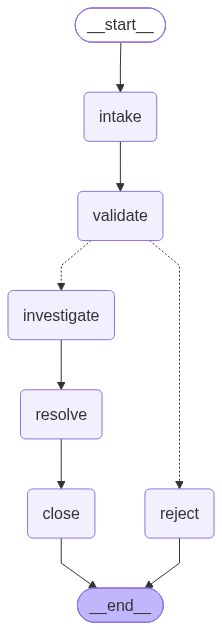

In [7]:
mermaid_diagram = app.get_graph().draw_mermaid()
print("Mermaid Graph Definition:\n")
print(mermaid_diagram)

try:
    png_bytes = app.get_graph().draw_mermaid_png()
    display(Image(png_bytes))
except Exception as exc:
    print(f"PNG rendering skipped (Mermaid text definition printed above): {exc}")

In [8]:
print("Recorded Execution Paths:")
for idx, r in enumerate(results, start=1):
    print(f"  Complaint #{idx} ({r['status']}): {format_workflow_path(r['workflow_path'])}")

Recorded Execution Paths:
  Complaint #1 (closed): intake → validate → investigate → resolve → close
  Complaint #2 (closed): intake → validate → investigate → resolve → close
  Complaint #3 (closed): intake → validate → investigate → resolve → close
  Complaint #4 (closed): intake → validate → investigate → resolve → close
  Complaint #5 (rejected): intake → validate → reject


---
## Step 6: Compare with a Single Unconstrained LLM Call

To contrast the structured LangGraph workflow against a freeform single-call baseline, we send both a valid complaint (`test_complaints[0]`) and an invalid complaint (`test_complaints[4]`) directly to `ask_single_llm(complaint, llm)` with no state graph, no validation guardrail, and no canonical `LORE` lookup. We also persist the complete run record to `execution_evidence.json`.

In [9]:
valid_complaint = test_complaints[0]
invalid_complaint = test_complaints[4]

single_llm_valid = ask_single_llm(valid_complaint, llm)
single_llm_invalid = ask_single_llm(invalid_complaint, llm)

print("=== VALID COMPLAINT COMPARISON ===")
print("Complaint:", valid_complaint)
print("\n[LangGraph Closure]:\n", results[0]["closure"])
print("\n[Single LLM Call]:\n", single_llm_valid)

print("\n" + "=" * 80 + "\n")
print("=== INVALID COMPLAINT COMPARISON ===")
print("Complaint:", invalid_complaint)
print("\n[LangGraph Closure]:\n", results[4]["closure"])
print("\n[Single LLM Call]:\n", single_llm_invalid)

evidence_payload = build_execution_evidence(
    model_name=DEFAULT_MODEL,
    temperature=DEFAULT_TEMPERATURE,
    manual_chain_state=manual_state,
    manual_chain_logs=manual_logs,
    complaint_results=complaint_results,
    mermaid_diagram=mermaid_diagram,
    single_llm_valid_response=single_llm_valid,
    single_llm_invalid_response=single_llm_invalid,
)
evidence_file = save_execution_evidence(evidence_payload)
print(f"\nSaved execution evidence to: {evidence_file.name}")

=== VALID COMPLAINT COMPARISON ===
Complaint: The Downside Up portal opens at different times each day. How do I predict when?

[LangGraph Closure]:
 Case closed under category 'portal'. Verified resolution: To effectively predict the opening of the Downside Up portal, monitor local electrical activity for fluctuations, as these changes indicate a weakening barrier between worlds. This approach will allow for timely awareness of potential portal appearances.

[Single LLM Call]:
 To predict when the Downside Up portal opens, you can follow these steps:

1. **Historical Data**: Gather data on the opening times of the portal over a period of time. Look for patterns or trends in the times it opens each day.

2. **Identify Patterns**: Analyze the data for any recurring patterns. For example, does it open at similar times on certain days of the week? Are there any specific intervals between openings?

3. **External Factors**: Consider any external factors that might influence the opening tim

### Post-Execution Comparison: LangGraph State Machine vs. Single LLM Call

Based on the captured outputs in `cell-06` (`manual_chain_run`), `cell-10` (`complaint_runs[0..4]`), and `cell-15` (`baseline_comparisons` in `execution_evidence.json`), the table below compares the structured LangGraph workflow against a single unconstrained LLM call (`gpt-4o-mini`, `temperature=0.0`):

| Dimension | LangGraph State Machine (`compile_workflow(llm)`) | One LLM Call (`ask_single_llm(complaint, llm)`) |
|---|---|---|
| **Same answer every run?** | **Conditional routing (`route_after_validation`) and rule nodes (`validate`, `close`, `reject`) are deterministic given the state, but LLM text generation is not identical across invocations even at `temperature=0.0`.** On the exact same portal complaint (`test_complaints[0]`), both `manual_chain_run` (`cell-06`) and `complaint_runs[0]` (`cell-10`) classified `category = 'portal'` and traversed `intake → validate → investigate → resolve → close`, yet their generated `investigation` and `resolution` texts differed (`manual_chain_run` added *"Implementing a real-time electrical monitoring system will enhance our ability to anticipate portal openings"*, whereas `complaint_runs[0]` wrote *"monitor local electrical activity for fluctuations, as these changes indicate a weakening barrier between worlds"*). | **Not established by this run.** Only one baseline response per complaint (`single_llm_valid` and `single_llm_invalid`) was captured in `cell-15`, so empirical repeatability of the single-LLM call was not tested across multiple invocations; structurally, it also lacks a multi-step state schema or deterministic routing. |
| **Invalid complaint rejected?** | **Yes for `complaint_runs[4]`, with deterministic rejection *after* an unsupported category is produced.** For `test_complaints[4]` (*"This is not a valid complaint about something random"*), `intake_node` returned `raw_category = 'other'` (`category = 'other'`), `validate_node` deterministically set `is_valid = False`, and `route_after_validation` routed to `reject_node` (`intake → validate → reject`, `status = 'rejected'`). However, the LLM classifier in `intake_node` can still misclassify an out-of-scope input into one of the four canonical categories. | **No.** Without a validation guardrail or rejection branch, the single LLM call did not reject `test_complaints[4]`; instead, it invented a humorous fictional complaint about a pet goldfish named *Bubbles* refusing to discuss Plato and existentialism. |
| **Path visible?** | **Yes.** Every node transition is recorded in `state["workflow_path"]` (e.g., `intake → validate → investigate → resolve → close` for complaints #1–#4 and `intake → validate → reject` for complaint #5) and logged via `[INTAKE]`, `[VALIDATE]`, `[INVESTIGATE]`, `[RESOLVE]`, `[CLOSE]`, and `[REJECT]` console lines. | **No.** Execution occurs inside one opaque `llm.invoke(...)` call with no intermediate state transitions, node logs, or branch visibility. |
| **Source of each claim?** | **Explicitly recorded in `state["evidence"]` (`LORE[category]`), making both grounded statements and LLM extrapolations directly auditable.** In `complaint_runs[0]`, the core mechanism (*portals open when the barrier is weak; timing follows electrical activity, not the clock*) is traceable to `LORE["portal"]`, and inspectability also exposes where `investigate_node` and `resolve_node` extrapolate beyond the intended prompt-level constraint (e.g., claiming electrical fluctuations predict a weakening barrier, asserting nosebleeds in `complaint_runs[2]`, or adding infrastructure/proximity controls in `complaint_runs[3]`). | **Unverified parametric memory.** The single-LLM baseline does not use the supplied `LORE` and introduces unsupported assumptions (such as lunar cycles, historical opening logs, official schedules, and community insights); while historical analysis and machine learning are not inherently contradictory to the lore, the baseline fails to identify the lore's stated link to electrical activity rather than clock time. |
| **Best for which client case?** | **Rule-governed, auditable workflows** where out-of-scope categories must be deterministically rejected once flagged by intake, execution paths must be logged, and generated claims must be audited against an explicit evidence record. | **Open-ended creative drafting or informal brainstorming** (such as generating humorous sample text) where strict input rejection, canonical evidence binding, and node-level auditability are unnecessary. |